<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" width="150" alt="VGI"></a>

# Does an item cap preserve the recent entries?

A feed can be reordered by editorial choices. If we ask for its first few entries and only then filter by time, how much of the recent bulletin survives? We will parse the same **synthetic** engineering bulletin as RSS, Atom and JSON Feed through the real released Go worker, check agreement, and measure the cap’s effect in SQL.

The ten fictional entries deliberately arrive out of chronological order. All dates and category labels are authored inputs, not observations of a real publisher. [Fixture notes](fixtures/README.md) describe the construction; [running instructions](README.md) describe the isolated environment.

## Choose the retrieval cap

`MAX_ITEMS` is a count of entries in **source order**, accepting integers 1–10. The fixed window is **[2026-01-13 12:00, 2026-01-15 12:00) UTC**: the lower endpoint is included and the anchor excluded. Keeping the window fixed isolates the cap’s effect. Edit the parameter, restart the kernel and run all cells.

In [1]:
MAX_ITEMS = 4  # Source-order entries per format; experiment: 8

In [2]:
from pathlib import Path

import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display

from notebook_support import chart, configure, prose, theme, verify_requests

server, server_thread, requests, base_url = configure(MAX_ITEMS)
theme()
connection = haybarn.connect()
connection.execute("SET TimeZone='UTC'")
rss_literal = "'" + Path("fixtures/feed.rss").read_text().replace("'", "''") + "'"
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaylimit = 20
%sql connection

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-feed-portable-d4melznt/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-feed-portable-d4melznt/pyproject.toml.

## Let the released worker fetch and parse

The HTTP server is a read-only loopback fixture. It serves the exact local documents and records requests; it does not emulate the parser. `github-auto` launches the pinned published worker without this repository’s source. Each fetch is materialized before display so JupySQL cannot accidentally repeat it.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'feed' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-feed@v0.5.0');
CREATE TABLE settings AS SELECT {{ MAX_ITEMS }}::INTEGER AS cap,
    TIMESTAMP '2026-01-15 12:00:00' AS anchor_utc,
    TIMESTAMP '2026-01-13 12:00:00' AS start_utc;
CREATE TABLE feed_metadata AS
SELECT 'RSS' AS format, * FROM feed.feed_info('{{ base_url }}/feed.rss')
UNION ALL SELECT 'Atom', * FROM feed.feed_info('{{ base_url }}/feed.atom')
UNION ALL SELECT 'JSON', * FROM feed.feed_info('{{ base_url }}/feed.json');
CREATE TABLE complete AS
SELECT 'RSS' AS format, * FROM feed.feed_items('{{ base_url }}/feed.rss', max_items := 0)
UNION ALL SELECT 'Atom', * FROM feed.feed_items('{{ base_url }}/feed.atom', max_items := 0)
UNION ALL SELECT 'JSON', * FROM feed.feed_items('{{ base_url }}/feed.json', max_items := 0);
CREATE TABLE capped AS
SELECT 'RSS' AS format, * FROM feed.feed_items('{{ base_url }}/feed.rss', max_items := {{ MAX_ITEMS }})
UNION ALL SELECT 'Atom', * FROM feed.feed_items('{{ base_url }}/feed.atom', max_items := {{ MAX_ITEMS }})
UNION ALL SELECT 'JSON', * FROM feed.feed_items('{{ base_url }}/feed.json', max_items := {{ MAX_ITEMS }});
CREATE TABLE inline_rss AS SELECT * FROM feed.feed_items({{ rss_literal }}, max_items := 0);

Running query in 'DuckDBPyConnection'

1 rows affected.

3 rows affected.

30 rows affected.

12 rows affected.

10 rows affected.

,Count


`max_items := 0` requests all entries up to the worker’s one-million-item safety ceiling; it is not an unlimited crawl. Our fixture is far below that bound. The inline RSS call parses the same text without HTTP, providing an independent transport comparison. Dates arrive as plain SQL `TIMESTAMP`; every authored timestamp denotes UTC.

In [4]:
%%sql availability <<
SELECT m.format, m.feed_type, m.item_count AS document_entries,
       count(c.guid) AS complete_rows,
       count(*) FILTER (WHERE c.published IS NULL) AS unknown_dates,
       count(*) FILTER (WHERE c.published < s.start_utc) AS before_window,
       count(*) FILTER (WHERE c.published >= s.anchor_utc) AS at_or_after_anchor,
       count(*) FILTER (WHERE c.published >= s.start_utc AND c.published < s.anchor_utc) AS recent_rows
FROM feed_metadata m JOIN complete c USING(format) CROSS JOIN settings s
GROUP BY m.format, m.feed_type, m.item_count ORDER BY m.format;

Running query in 'DuckDBPyConnection'

In [5]:
display(availability)
prose(
    "The metadata count describes the whole document, not the capped result. Unknown "
    "dates, older entries and entries at/after the anchor are separate outcomes. The "
    "next comparison uses GUID, source position, title, link, publication instant and "
    "sorted category labels; format-specific summary or update fields are outside that "
    "contract."
)

,format,feed_type,document_entries,complete_rows,unknown_dates,before_window,at_or_after_anchor,recent_rows
0,Atom,atom,10,10,0,2,2,6
1,JSON,json,10,10,0,2,2,6
2,RSS,rss,10,10,0,2,2,6


The metadata count describes the whole document, not the capped result. Unknown dates, older entries and entries at/after the anchor are separate outcomes. The next comparison uses GUID, source position, title, link, publication instant and sorted category labels; format-specific summary or update fields are outside that contract.

## Separate source order from publication time

SQL joins the capped rows back to the complete baseline by format and GUID. An entry is recent only when its known publication time falls inside the fixed half-open window. No unknown timestamp is converted to zero age, and no future timestamp is treated as a recent observation.

In [6]:
%%sql
CREATE TABLE classified AS
SELECT a.*, b.guid IS NOT NULL AS retrieved,
       date_diff('second', a.published, s.anchor_utc) / 3600.0 AS age_hours,
       CASE WHEN a.published IS NULL THEN 'Unknown date'
            WHEN a.published < s.start_utc THEN 'Before window'
            WHEN a.published >= s.anchor_utc THEN 'At/after anchor'
            ELSE 'Recent' END AS time_class
FROM complete a LEFT JOIN capped b ON a.format=b.format AND a.guid=b.guid
CROSS JOIN settings s;
CREATE TABLE coverage AS
SELECT format, count(*) AS complete_rows,
       count(*) FILTER (WHERE retrieved) AS retrieved_rows,
       count(*) FILTER (WHERE time_class='Recent') AS recent_total,
       count(*) FILTER (WHERE time_class='Recent' AND retrieved) AS recent_retrieved,
       count(*) FILTER (WHERE time_class='Recent' AND NOT retrieved) AS recent_missed,
       100.0 * count(*) FILTER (WHERE time_class='Recent' AND retrieved)
           / nullif(count(*) FILTER (WHERE time_class='Recent'), 0) AS recent_recall_pct
FROM classified GROUP BY format;
CREATE TABLE ordered_rss AS SELECT seq+1 AS source_position, title, age_hours,
       time_class, retrieved FROM classified WHERE format='RSS';

Running query in 'DuckDBPyConnection'

30 rows affected.

3 rows affected.

10 rows affected.

,Count


In [7]:
%%sql coverage_frame <<
SELECT * FROM coverage ORDER BY format;

Running query in 'DuckDBPyConnection'

In [8]:
display(coverage_frame)
r = coverage_frame.loc[coverage_frame["format"].eq("RSS")].iloc[0]
prose(
    f"With a cap of **{MAX_ITEMS} entries**, RSS retains **{int(r.recent_retrieved)} of "
    f"{int(r.recent_total)} recent entries** ({r.recent_recall_pct:.1f}% recall), "
    f"leaving **{int(r.recent_missed)}** recent entries outside the retrieved prefix. "
    f"Atom and JSON are checked against the same normalized fields below. Recall "
    f"describes these authored entries; it does not estimate any publisher’s real-world "
    f"behavior."
)

,format,complete_rows,retrieved_rows,recent_total,recent_retrieved,recent_missed,recent_recall_pct
0,Atom,10,4,6,2,4,33.333333
1,JSON,10,4,6,2,4,33.333333
2,RSS,10,4,6,2,4,33.333333


With a cap of **4 entries**, RSS retains **2 of 6 recent entries** (33.3% recall), leaving **4** recent entries outside the retrieved prefix. Atom and JSON are checked against the same normalized fields below. Recall describes these authored entries; it does not estimate any publisher’s real-world behavior.

In [9]:
%%sql positions <<
SELECT * FROM ordered_rss ORDER BY source_position;

Running query in 'DuckDBPyConnection'

findfont: Failed to find font weight semibold for Arial, now using 700.


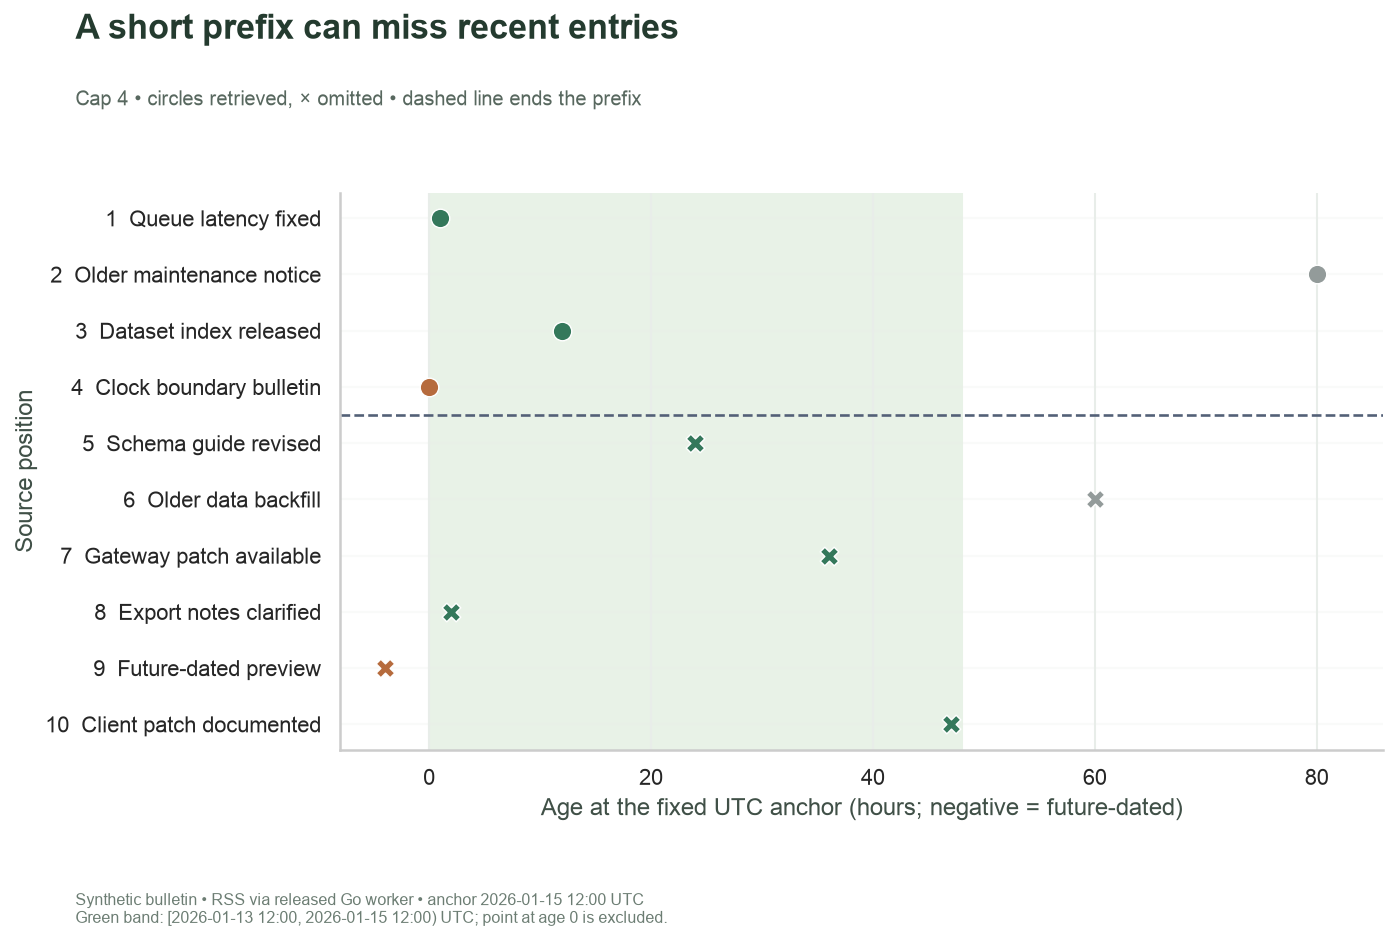

In [10]:
fig, ax = plt.subplots(figsize=(10, 6.6))
ax.axvspan(0, 48, color="#E8F2E7", zorder=0, label="Recent window: 0 < age ≤ 48 h")
colors = {
    "Recent": "#34785B",
    "Before window": "#939B9A",
    "At/after anchor": "#B66B3D",
    "Unknown date": "#836CB1",
}
for row in positions.itertuples():
    if np.isfinite(row.age_hours):
        ax.scatter(
            row.age_hours,
            row.source_position,
            s=85,
            marker="o" if row.retrieved else "X",
            color=colors[row.time_class],
            edgecolor="white",
            linewidth=0.7,
            zorder=3,
        )
ax.axhline(MAX_ITEMS + 0.5, color="#536077", linestyle="--", linewidth=1.3)
ax.set_yticks(
    positions.source_position,
    [f"{int(p)}  {t}" for p, t in zip(positions.source_position, positions.title, strict=True)],
)
ax.invert_yaxis()
ax.set_xlabel("Age at the fixed UTC anchor (hours; negative = future-dated)")
ax.set_ylabel("Source position")
ax.set_xlim(min(-8, positions.age_hours.min() - 4), positions.age_hours.max() + 6)
ax.grid(axis="y", alpha=0.25)
chart(
    fig,
    "A short prefix can miss recent entries",
    f"Cap {MAX_ITEMS} • circles retrieved, × omitted • dashed line ends the prefix",
    "Synthetic bulletin • RSS via released Go worker • anchor 2026-01-15 12:00 UTC\n"
    "Green band: [2026-01-13 12:00, 2026-01-15 12:00) UTC; point at age 0 is excluded.",
)

The cap boundary cuts across **source positions**, while the green band selects **publication instants**. Sorting the already capped result cannot recover omitted entries. Next we ask whether this omission is distributed evenly across the bulletin’s topic labels.

In [11]:
%%sql categories <<
WITH memberships AS (
    SELECT DISTINCT guid, retrieved, unnest(categories) AS category
    FROM classified WHERE format='RSS' AND time_class='Recent'
)
SELECT category, count(*) AS recent_total,
       count(*) FILTER (WHERE retrieved) AS recent_retrieved,
       count(*) FILTER (WHERE NOT retrieved) AS recent_missed,
       100.0 * count(*) FILTER (WHERE retrieved) / count(*) AS recall_pct
FROM memberships GROUP BY category ORDER BY category;

Running query in 'DuckDBPyConnection'

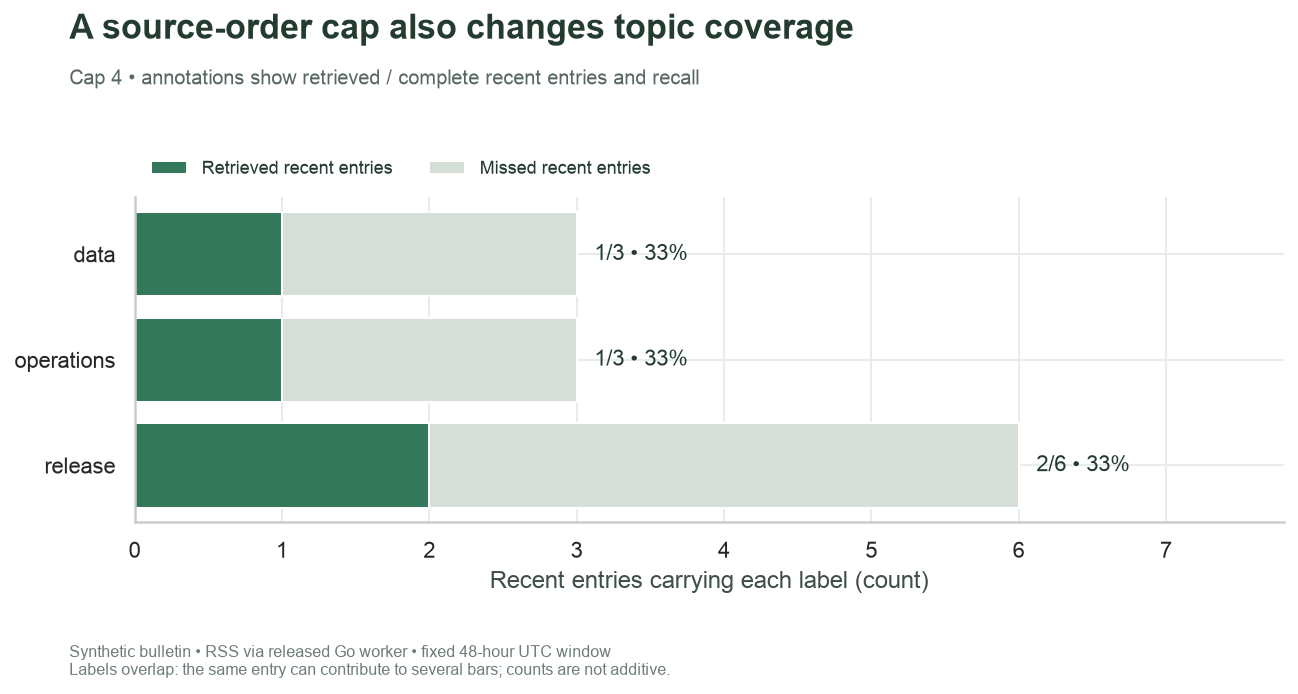

In [12]:
fig, ax = plt.subplots(figsize=(9.3, 4.8))
y = np.arange(len(categories))
ax.barh(y, categories.recent_retrieved, color="#34785B", label="Retrieved recent entries")
ax.barh(
    y,
    categories.recent_missed,
    left=categories.recent_retrieved,
    color="#D5DFD8",
    label="Missed recent entries",
)
for i, row in enumerate(categories.itertuples()):
    ax.text(
        row.recent_total + 0.12,
        i,
        f"{row.recent_retrieved}/{row.recent_total} • {row.recall_pct:.0f}%",
        va="center",
        fontsize=11,
    )
ax.set_yticks(y, categories.category)
ax.invert_yaxis()
ax.set_xlabel("Recent entries carrying each label (count)")
ax.set_xlim(0, categories.recent_total.max() + 1.8)
ax.xaxis.get_major_locator().set_params(integer=True)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.01), ncol=2, fontsize=9)
chart(
    fig,
    "A source-order cap also changes topic coverage",
    f"Cap {MAX_ITEMS} • annotations show retrieved / complete recent entries and recall",
    "Synthetic bulletin • RSS via released Go worker • fixed 48-hour UTC window\n"
    "Labels overlap: the same entry can contribute to several bars; counts are not additive.",
)

In [13]:
lo = categories.sort_values(["recall_pct", "category"]).iloc[0]
hi = categories.sort_values(["recall_pct", "category"], ascending=[False, True]).iloc[0]
if hi.recall_pct > lo.recall_pct:
    result = (
        f"Recent **{lo.category}** entries have {lo.recall_pct:.1f}% recall versus "
        f"{hi.recall_pct:.1f}% for **{hi.category}**. The cap affects topic coverage "
        f"unevenly in this constructed ordering."
    )
else:
    result = (
        f"All topic labels have the same {lo.recall_pct:.1f}% recall at this cap. Equal "
        f"recall here follows this particular ordering, not a general guarantee."
    )
prose(
    result + " An entry can carry multiple labels, so adding the bar totals would double-count memberships. "
    "The full-feed baseline is necessary to quantify omissions; "
    "a capped feed alone cannot reveal what it did not return."
)

All topic labels have the same 33.3% recall at this cap. Equal recall here follows this particular ordering, not a general guarantee. An entry can carry multiple labels, so adding the bar totals would double-count memberships. The full-feed baseline is necessary to quantify omissions; a capped feed alone cannot reveal what it did not return.

## Verify the inference

These checks test structural relationships rather than a preferred ranking: document counts, common-field format equivalence, HTTP/inline agreement, the exact prefix rule, and the partition of time states. A failed check stops the run before it can replace the saved example.

In [14]:
%%sql checks <<
WITH common AS (
    SELECT format, seq, guid, title, link, published, list_sort(categories) AS categories FROM complete
), differences AS (
    (SELECT seq,guid,title,link,published,categories FROM common WHERE format='RSS'
     EXCEPT SELECT seq,guid,title,link,published,categories FROM common WHERE format='Atom')
    UNION ALL
    (SELECT seq,guid,title,link,published,categories FROM common WHERE format='RSS'
     EXCEPT SELECT seq,guid,title,link,published,categories FROM common WHERE format='JSON')
), transport_difference AS (
    (SELECT seq,guid,title,link,published,list_sort(categories) FROM complete WHERE format='RSS'
     EXCEPT SELECT seq,guid,title,link,published,list_sort(categories) FROM inline_rss)
    UNION ALL
    (SELECT seq,guid,title,link,published,list_sort(categories) FROM inline_rss
     EXCEPT SELECT seq,guid,title,link,published,list_sort(categories) FROM complete WHERE format='RSS')
)
SELECT 'Metadata count equals uncapped rows' AS check_name,
       NOT EXISTS (SELECT 1 FROM coverage JOIN feed_metadata USING(format) WHERE complete_rows<>item_count) AS passed
UNION ALL SELECT 'GUIDs are present and unique within format',
       NOT EXISTS (SELECT format,guid FROM complete GROUP BY format,guid HAVING guid IS NULL OR guid='' OR count(*)<>1)
UNION ALL SELECT 'Three formats agree on normalized common fields',
       NOT EXISTS (SELECT 1 FROM differences) AND (SELECT count(DISTINCT complete_rows)=1 FROM coverage)
UNION ALL SELECT 'HTTP and inline RSS agree in both directions', NOT EXISTS (SELECT 1 FROM transport_difference)
UNION ALL SELECT 'Capped membership is exactly the source prefix',
       NOT EXISTS (SELECT 1 FROM classified CROSS JOIN settings WHERE retrieved<>(seq<cap))
UNION ALL SELECT 'Capped count equals min(cap, complete count)',
       NOT EXISTS (SELECT 1 FROM coverage CROSS JOIN settings WHERE retrieved_rows<>least(cap,complete_rows))
UNION ALL SELECT 'Time classes partition all complete rows',
       (SELECT count(*)=sum(CASE WHEN time_class IN ('Recent','Before window','At/after anchor','Unknown date') THEN 1 ELSE 0 END) FROM classified)
UNION ALL SELECT 'Recent retrieved plus missed equals complete',
       NOT EXISTS (SELECT 1 FROM coverage WHERE recent_retrieved+recent_missed<>recent_total OR recent_recall_pct NOT BETWEEN 0 AND 100)
UNION ALL SELECT 'All three format detections match their labels',
       NOT EXISTS (SELECT 1 FROM feed_metadata WHERE lower(format)<>feed_type)
UNION ALL SELECT 'Coverage is equal across equivalent formats',
       (SELECT count(DISTINCT recent_retrieved)=1 AND count(DISTINCT recent_total)=1 FROM coverage);

Running query in 'DuckDBPyConnection'

In [15]:
display(checks)
assert checks.passed.all(), checks.loc[~checks.passed].to_dict("records")
prose(verify_requests(requests))

,check_name,passed
0,Metadata count equals uncapped rows,True
1,GUIDs are present and unique within format,True
2,Three formats agree on normalized common fields,True
3,HTTP and inline RSS agree in both directions,True
4,Capped membership is exactly the source prefix,True
5,"Capped count equals min(cap, complete count)",True
6,Time classes partition all complete rows,True
7,Recent retrieved plus missed equals complete,True
8,All three format detections match their labels,True
9,Coverage is equal across equivalent formats,True


HTTP audit passed: nine real worker requests, three per synthetic format. Inline RSS parsing makes no HTTP request.

## Experiment: double only the cap

Change **`MAX_ITEMS` from 4 to 8**, restart and run all, or use the separate-output command in the README. Predict that recent-entry recall cannot decrease when the same immutable document supplies a longer prefix. Compare the coverage table, cap boundary and per-topic bars. A larger cap may still miss recent entries, and the topic labels need not improve equally.

The documents, time window and definition of “recent” stay fixed; this isolates one retrieval choice. It does **not** measure network efficiency: the worker fetches and parses the whole document before limiting emitted rows. For these small inputs, fetching the full baseline then filtering and ordering in SQL is feasible. Real feeds may be incomplete histories, even with no requested cap. Reset **`MAX_ITEMS = 4`** to restore the saved example.

In [16]:
connection.close()
server.shutdown()
server.server_close()
server_thread.join(timeout=2)

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" width="240" alt="Query.Farm"></a>